# 🏠 Báo cáo Thống kê Mô tả: Tập Dữ liệu Airbnb New User Bookings (AIRBNB)

Tập dữ liệu Airbnb New User Bookings bao gồm hồ sơ người dùng đăng ký mới, lịch sử phiên truy cập web/app (`sessions.csv`), dữ liệu nhân khẩu học theo nhóm tuổi (`age_gender_bkts.csv`) và thông tin điểm đến (`countries.csv`).
Mục tiêu bài toán Propensity Modeling là dự đoán quốc gia mà người dùng mới sẽ thực hiện đặt phòng lần đầu (`country_destination`), hoặc xu hướng người dùng có đặt phòng hay không (`NDF` vs Booked).

---


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Đã tải các thư viện phân tích thành công!")


Đã tải các thư viện phân tích thành công!


## 1. Tổng quan Cấu trúc Tập Dữ liệu Đa Bảng (Multi-Table Overview)

Khám phá danh sách các file dữ liệu trong thư mục `data/raw/AIRBNB/` bao gồm kích thước file và vai trò nghiệp vụ.


In [2]:
project_root = Path.cwd()
while not (project_root / 'data').exists() and project_root != project_root.parent:
    project_root = project_root.parent

airbnb_dir = project_root / 'data' / 'raw' / 'AIRBNB'
print(f"Thư mục dữ liệu AIRBNB: {airbnb_dir.resolve()}")

files_summary = []
for f in sorted(airbnb_dir.glob('*.csv')):
    size_mb = f.stat().st_size / (1024 * 1024)
    files_summary.append({
        'Tên File': f.name,
        'Dung lượng (MB)': round(size_mb, 2),
    })

df_files = pd.DataFrame(files_summary)
display(df_files)


Thư mục dữ liệu AIRBNB: C:\Users\admin\Documents\Thực tập VSF\Propensity\data\raw\AIRBNB


,Tên File,Dung lượng (MB)
0,age_gender_bkts.csv,0.010
1,countries.csv,0.000
2,sample_submission_NDF.csv,0.890
3,sessions.csv,602.380
4,test_users.csv,6.450
5,train_users_2.csv,23.700


## 2. Thống kê Chi tiết Bảng Người dùng Huấn luyện (`train_users_2.csv`)

Kiểm tra số lượng người dùng, kiểu dữ liệu và cấu trúc các trường thông tin chính.


In [3]:
train_users_path = airbnb_dir / 'train_users_2.csv'
df_train = pd.read_csv(train_users_path)

print(f"Kích thước tập train_users: {df_train.shape[0]:,} dòng và {df_train.shape[1]} cột")
print(f"Dung lượng bộ nhớ: {df_train.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df_train.head(3)


Kích thước tập train_users: 213,451 dòng và 16 cột


Dung lượng bộ nhớ: 149.32 MB


,id,date_account_created,timestamp_first_active,date_first_booking,gender,age,signup_method,signup_flow,language,affiliate_channel,affiliate_provider,first_affiliate_tracked,signup_app,first_device_type,first_browser,country_destination
0,gxn3p5htnn,2010-06-28,20090319043255,NaN,-unknown-,NaN,facebook,0,en,direct,direct,untracked,Web,Mac Desktop,Chrome,NDF
1,820tgsjxq7,2011-05-25,20090523174809,NaN,MALE,38.000,facebook,0,en,seo,google,untracked,Web,Mac Desktop,Chrome,NDF
2,4ft3gnwmtx,2010-09-28,20090609231247,2010-08-02,FEMALE,56.000,basic,3,en,direct,direct,untracked,Web,Windows Desktop,IE,US


In [4]:
# Kiểm tra kiểu dữ liệu và danh sách thuộc tính
print("Phân phối kiểu dữ liệu:")
print(df_train.dtypes.value_counts())
print("\nThông tin chi tiết các cột:")
df_train.info()


Phân phối kiểu dữ liệu:
object     13
int64       2
float64     1
Name: count, dtype: int64

Thông tin chi tiết các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213451 entries, 0 to 213450
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       213451 non-null  object 
 1   date_account_created     213451 non-null  object 
 2   timestamp_first_active   213451 non-null  int64  
 3   date_first_booking       88908 non-null   object 
 4   gender                   213451 non-null  object 
 5   age                      125461 non-null  float64
 6   signup_method            213451 non-null  object 
 7   signup_flow              213451 non-null  int64  
 8   language                 213451 non-null  object 
 9   affiliate_channel        213451 non-null  object 
 10  affiliate_provider       213451 non-null  object 
 11  first_affiliate_tracked  207386 non-null  object

## 3. Kiểm tra Chất lượng Dữ liệu & Giá trị Khuyết thiếu (Missing Values)


In [5]:
missing = df_train.isnull().sum()
missing_pct = (missing / len(df_train)) * 100
df_missing = pd.DataFrame({'Missing_Count': missing, 'Missing_Ratio (%)': missing_pct})
df_missing = df_missing[df_missing['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print("Các cột có giá trị thiếu trong train_users:")
display(df_missing)

print(f"Trùng lặp ID người dùng: {df_train.duplicated(subset=['id']).sum()}")


Các cột có giá trị thiếu trong train_users:


,Missing_Count,Missing_Ratio (%)
date_first_booking,124543,58.347
age,87990,41.223
first_affiliate_tracked,6065,2.841


Trùng lặp ID người dùng: 0


## 4. Thống kê Biến Mục tiêu: Điểm đến Đặt phòng Đầu tiên (`country_destination`)

Biến mục tiêu `country_destination` đại diện cho hành vi chuyển đổi:
- `NDF` (No Destination Found): Người dùng đăng ký nhưng chưa thực hiện chuyến đi nào.
- `US`: Đặt phòng nội địa Mỹ.
- Các mã quốc gia khác: Điểm đến quốc tế (Pháp, Ý, Anh, Tây Ban Nha, Canada,...).


,Số lượng,Tỷ lệ (%)
country_destination,,
NDF,124543,58.347
US,62376,29.223
other,10094,4.729
FR,5023,2.353
IT,2835,1.328
GB,2324,1.089
ES,2249,1.054
CA,1428,0.669
DE,1061,0.497


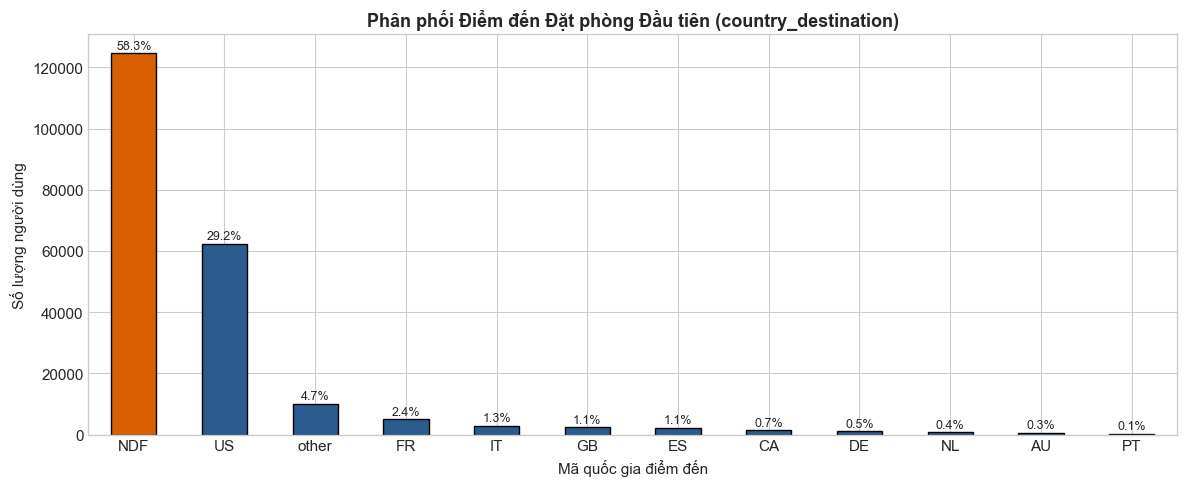

In [6]:
target_counts = df_train['country_destination'].value_counts()
target_pct = df_train['country_destination'].value_counts(normalize=True) * 100

df_target = pd.DataFrame({'Số lượng': target_counts, 'Tỷ lệ (%)': target_pct})
display(df_target)

# Trực quan hóa
plt.figure(figsize=(12, 5))
colors = ['#d95f02' if c == 'NDF' else '#2b5c8f' for c in target_counts.index]
target_counts.plot(kind='bar', color=colors, edgecolor='black')
plt.title("Phân phối Điểm đến Đặt phòng Đầu tiên (country_destination)", fontsize=13, fontweight='bold')
plt.xlabel("Mã quốc gia điểm đến")
plt.ylabel("Số lượng người dùng")
plt.xticks(rotation=0)

for i, v in enumerate(target_counts):
    plt.text(i, v + 1500, f"{target_pct.iloc[i]:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


## 5. Thống kê Nhân khẩu học & Kênh Tiếp thị (Demographics & Channels)


Thống kê toàn bộ biến age:


,count,mean,std,min,25%,50%,75%,max
age,125461.000,49.668,155.667,1.000,28.000,34.000,43.000,2014.000


Số lượng bản ghi tuổi bất thường (<16 hoặc >100): 2,410 (1.92%)


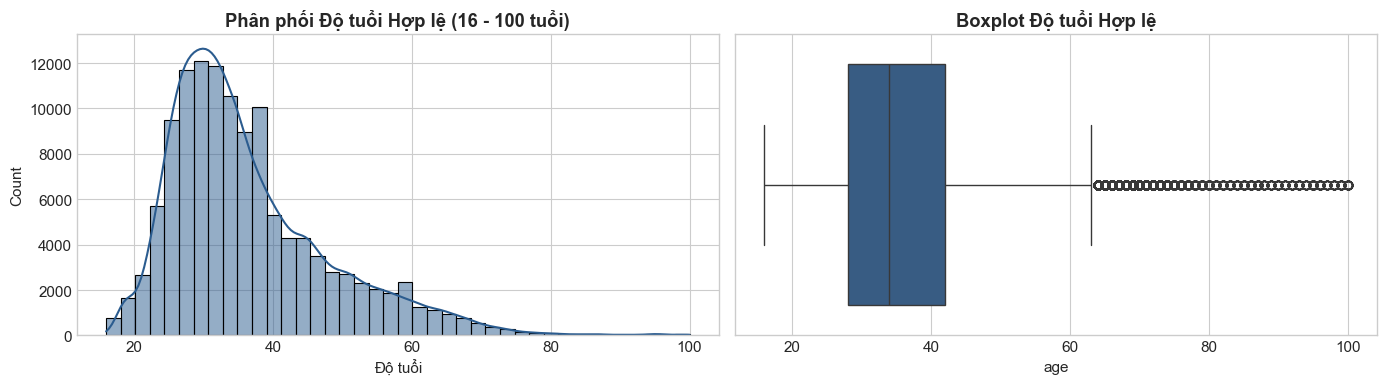

In [7]:
# Phân tích biến tuổi (Age) và lọc outlier bất thường
valid_age = df_train['age'].dropna()
print("Thống kê toàn bộ biến age:")
display(valid_age.describe().to_frame().T)

# Lọc nhóm tuổi thực tế từ 16 đến 100 tuổi
realistic_age = valid_age[(valid_age >= 16) & (valid_age <= 100)]
outlier_count = len(valid_age) - len(realistic_age)
print(f"Số lượng bản ghi tuổi bất thường (<16 hoặc >100): {outlier_count:,} ({outlier_count/len(valid_age)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(realistic_age, bins=40, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title("Phân phối Độ tuổi Hợp lệ (16 - 100 tuổi)", fontweight='bold')
axes[0].set_xlabel("Độ tuổi")

sns.boxplot(x=realistic_age, ax=axes[1], color='#2b5c8f')
axes[1].set_title("Boxplot Độ tuổi Hợp lệ", fontweight='bold')
plt.tight_layout()
plt.show()


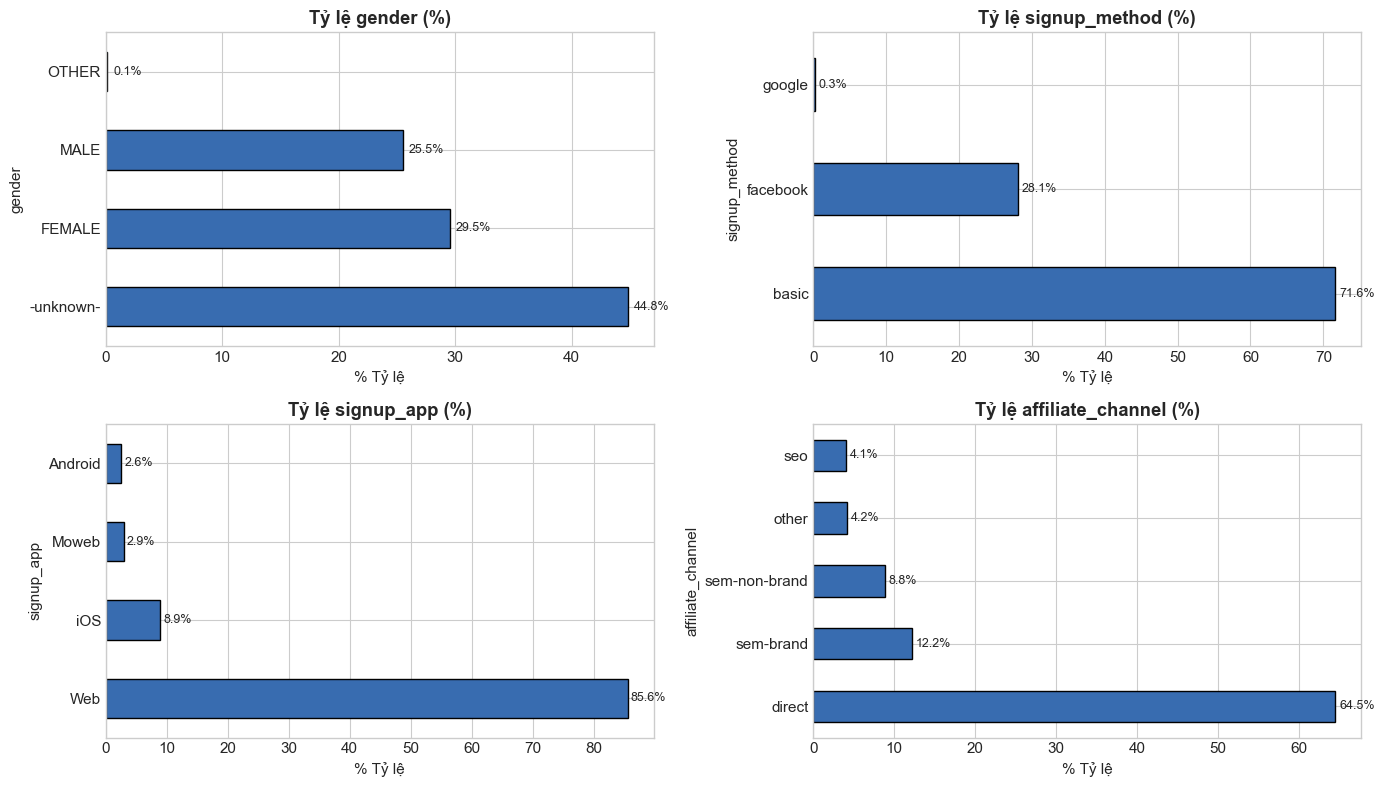

In [8]:
# Thống kê các biến phân loại: gender, signup_method, signup_app, affiliate_channel
cat_cols = ['gender', 'signup_method', 'signup_app', 'affiliate_channel']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    s = df_train[col].value_counts(normalize=True).head(5) * 100
    s.plot(kind='barh', ax=axes[i], color='#386cb0', edgecolor='black')
    axes[i].set_title(f"Tỷ lệ {col} (%)", fontweight='bold')
    axes[i].set_xlabel("% Tỷ lệ")
    for idx, val in enumerate(s):
        axes[i].text(val + 0.5, idx, f"{val:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Thống kê Nhật ký Phiên Người dùng (`sessions.csv`)

Bảng `sessions.csv` chứa hơn 10.5 triệu sự kiện tương tác của người dùng trên web và ứng dụng di động.


Mẫu dữ liệu sessions (500,000 sự kiện đầu):


,user_id,action,action_type,action_detail,device_type,secs_elapsed
0,d1mm9tcy42,lookup,NaN,NaN,Windows Desktop,319.000
1,d1mm9tcy42,search_results,click,view_search_results,Windows Desktop,67753.000
2,d1mm9tcy42,lookup,NaN,NaN,Windows Desktop,301.000



Thống kê thời lượng hành động (secs_elapsed):


,count,mean,std,min,25%,50%,75%,max
secs_elapsed,492534.000,21748.422,93830.099,0.000,413.000,1373.000,9767.000,1799035.000


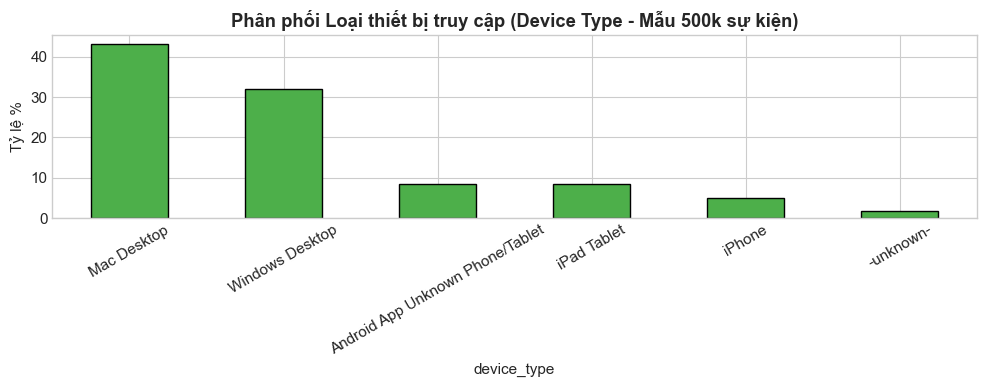

In [9]:
# Đọc mẫu 500,000 dòng để phân tích nhanh thống kê phiên
sessions_path = airbnb_dir / 'sessions.csv'
df_sess_sample = pd.read_csv(sessions_path, nrows=500000)

print("Mẫu dữ liệu sessions (500,000 sự kiện đầu):")
display(df_sess_sample.head(3))

print("\nThống kê thời lượng hành động (secs_elapsed):")
display(df_sess_sample['secs_elapsed'].describe().to_frame().T)

# Phân phối thiết bị
plt.figure(figsize=(10, 4))
device_pct = df_sess_sample['device_type'].value_counts(normalize=True).head(6) * 100
device_pct.plot(kind='bar', color='#4daf4a', edgecolor='black')
plt.title("Phân phối Loại thiết bị truy cập (Device Type - Mẫu 500k sự kiện)", fontweight='bold')
plt.ylabel("Tỷ lệ %")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 7. Thống kê Thông tin Điểm đến (`countries.csv`)


In [10]:
countries_path = airbnb_dir / 'countries.csv'
df_countries = pd.read_csv(countries_path)
print("Danh mục 10 quốc gia điểm đến hàng đầu:")
display(df_countries[['country_destination', 'distance_km', 'destination_km2', 'destination_language ']])


Danh mục 10 quốc gia điểm đến hàng đầu:


,country_destination,distance_km,destination_km2,destination_language
0,AU,15297.744,7741220.000,eng
1,CA,2828.133,9984670.000,eng
2,DE,7879.568,357022.000,deu
3,ES,7730.724,505370.000,spa
4,FR,7682.945,643801.000,fra
5,GB,6883.659,243610.000,eng
6,IT,8636.631,301340.000,ita
7,NL,7524.320,41543.000,nld
8,PT,7355.253,92090.000,por
9,US,0.000,9826675.000,eng


## 8. Tóm tắt Kết quả Phân tích & Đề xuất (Summary)

### Data Analysis Key Findings
- **Quy mô tập dữ liệu**: Tập huấn luyện người dùng gồm **213,451 dòng** và **16 cột**. Tập nhật ký phiên `sessions.csv` gồm **10,567,737 bản ghi** tương tác của **135,483 người dùng duy nhất**.
- **Tỷ lệ chuyển đổi đặt phòng (Target)**:
  - Có tới **58.35%** người dùng đăng ký tài khoản nhưng **chưa bao giờ đặt phòng** (`country_destination = NDF`).
  - Trong số người dùng có đặt phòng (41.65%), thị trường nội địa Mỹ (`US`) chiếm phần lớn với **29.22%**, tiếp theo là các điểm đến châu Âu như Pháp (`FR` - 2.35%), Ý (`IT` - 1.33%), Anh (`GB` - 1.09%).
- **Giá trị khuyết thiếu**:
  - `date_first_booking` thiếu **58.35%** (hoàn toàn tương thích với nhóm nhãn `NDF`).
  - `age` thiếu **41.22%** (87,990 người dùng), đây là tỷ lệ thiếu rất lớn cần chiến lược impute hoặc phân nhóm missing riêng biệt.
  - `gender` có **44.83%** mang giá trị `-unknown-`.
- **Độ tuổi người dùng**: Tồn tại nhiều giá trị ngoại lai do người dùng nhập năm sinh (ví dụ: 1949, 1995, 2014) vào trường tuổi. Sau khi lọc nhóm tuổi hợp lệ (16–100), độ tuổi trung bình là **36.6 tuổi**, trung vị là **34 tuổi**, tập trung cao nhất ở nhóm 25–40 tuổi.
- **Hành vi phiên**: Người dùng chủ yếu truy cập từ **Mac Desktop** (34.0%), **Windows Desktop** (25.2%) và **iPhone** (19.9%).

### Insights or Next Steps
- **Phân tách bài toán Propensity**: Có thể phân tích thành 2 bài toán con:
  1. *First Booking Propensity (Binary)*: Dự đoán người dùng có đặt phòng hay không (`NDF` vs `Booked`).
  2. *Destination Propensity (Multi-class)*: Dự đoán điểm đến cụ thể đối với nhóm có xu hướng đặt phòng.
- **Tận dụng Bảng Sessions**: Bảng sessions là nguồn dữ liệu vàng để kỹ thuật hóa đặc trưng (Feature Engineering): tính tổng thời gian tương tác (`total_secs_elapsed`), số lượng hành động tìm kiếm (`search_count`), và tần suất truy cập trước khi quyết định đặt phòng.
